#### Setup

In [21]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from src.paths import load_ccep, runs, electrodes_tsv

cc = load_ccep()
print(len(cc), "patients")

74 patients


###  All electrodes of all patients in one table

In [22]:
E = pd.concat(
    [electrodes_tsv(p["id"], p["ses"]).assign(patient=p["id"]) for p in cc],
    ignore_index=True,
)
print(E.shape)
for col in ["soz", "resected", "edge", "group"]:
    print(col, E[col].value_counts(dropna=False).to_dict())

(8655, 16)
soz {'no': 8302, 'yes': 353}
resected {'no': 7999, 'yes': 656}
edge {'no': 8482, 'yes': 173}
group {'grid': 4410, 'other': 3123, 'strip': 920, 'depth': 202}


#### Per patient: how many SOZ, resected and edge electrodes

In [23]:
yes = lambda s: (s == "yes").sum()

per = E.groupby("patient").agg(
    n_electrodes=("name", "size"),
    n_soz=("soz", yes),
    n_resected=("resected", yes),
    n_edge=("edge", yes),
)
per["soz_annotated"] = per["n_soz"] > 0
per["has_resection"] = per["n_resected"] > 0
per

,n_electrodes,n_soz,n_resected,n_edge,soz_annotated,has_resection
patient,,,,,,
sub-ccepAgeUMCU01,133,0,0,0,False,False
sub-ccepAgeUMCU02,96,0,0,0,False,False
sub-ccepAgeUMCU03,133,0,0,0,False,False
sub-ccepAgeUMCU04,128,0,0,0,False,False
sub-ccepAgeUMCU05,133,0,0,0,False,False
...,...,...,...,...,...,...
sub-ccepAgeUMCU70,68,0,0,0,False,False
sub-ccepAgeUMCU71,68,0,0,0,False,False
sub-ccepAgeUMCU72,133,0,0,0,False,False


Patients: SOZ marked? Resection marked?

In [24]:
pd.crosstab(per["soz_annotated"], per["has_resection"], margins=True)

has_resection,False,True,All
soz_annotated,,,
False,33,5,38
True,1,35,36
All,34,40,74


Electrodes: SOZ vs. resected

In [25]:
pd.crosstab(E["soz"], E["resected"], margins=True)

resected,no,yes,All
soz,,,
no,7887,415,8302
yes,112,241,353
All,7999,656,8655


SOZ electrodes that were NOT removed (left in the brain)

In [26]:
E["soz_not_resected"] = (E["soz"] == "yes") & (E["resected"] == "no")
per["n_soz_not_resected"] = E.groupby("patient")["soz_not_resected"].sum()

per[per["n_soz_not_resected"] > 0].sort_values("n_soz_not_resected", ascending=False)

,n_electrodes,n_soz,n_resected,n_edge,soz_annotated,has_resection,n_soz_not_resected
patient,,,,,,,
sub-ccepAgeUMCU58,133,37,23,4,True,True,22
sub-ccepAgeUMCU65,133,18,8,6,True,True,13
sub-ccepAgeUMCU47,133,11,0,0,True,False,11
sub-ccepAgeUMCU61,133,19,20,16,True,True,9
sub-ccepAgeUMCU07,130,24,48,8,True,True,8
sub-ccepAgeUMCU48,93,9,2,10,True,True,7
sub-ccepAgeUMCU42,133,20,51,6,True,True,7
sub-ccepAgeUMCU36,133,7,13,8,True,True,6
sub-ccepAgeUMCU62,133,11,6,2,True,True,5


How many N1 responses and stimulated pairs touch flagged electrodes?

In [27]:
rows = []
for p in cc:
    el = electrodes_tsv(p["id"], p["ses"]).set_index("name")
    for r in runs(p):
        rec = el.reindex(r["channel_names"])   # match by name, not by position
        n1 = r["n1_peak_sample"]
        for flag in ["soz", "resected"]:
            flagged = rec[flag].eq("yes").values
            rows.append(dict(
                patient=p["id"],
                run=r["runName"],
                flag=flag,
                rec_channels_flagged=flagged.sum(),
                n1_at_flagged=int(np.sum(~np.isnan(n1[flagged, :]))),
                n1_total=int(np.sum(~np.isnan(n1))),
                stim_pairs_flagged=sum(
                    el.reindex(pair.split("-"))[flag].eq("yes").any()
                    for pair in r["stimpair_names"]
                ),
                stim_pairs_total=len(r["stimpair_names"]),
            ))

R = pd.DataFrame(rows)
summary = R.groupby("flag")[["rec_channels_flagged", "n1_at_flagged", "n1_total",
                             "stim_pairs_flagged", "stim_pairs_total"]].sum()
summary["share_n1_lost_%"] = (100 * summary["n1_at_flagged"] / summary["n1_total"]).round(1)
summary

,rec_channels_flagged,n1_at_flagged,n1_total,stim_pairs_flagged,stim_pairs_total,share_n1_lost_%
flag,,,,,,
resected,1024,4134,40168,690,4907,10.3
soz,528,2404,40168,415,4907,6.0


In [28]:
rows = []
for p in cc:
    el = electrodes_tsv(p["id"], p["ses"])
    n1s = [r["n1_peak_sample"] for r in runs(p)]
    rows.append(dict(
        patient=p["id"],
        age=p["age"],
        soz_annotated=(el["soz"] == "yes").any(),
        has_resection=(el["resected"] == "yes").any(),
        n_electrodes=len(el),
        n_depth=(el["group"] == "depth").sum(),
        n_stim_pairs=sum(a.shape[1] for a in n1s),
        n1_rate=np.mean(np.concatenate([(~np.isnan(a)).ravel() for a in n1s])),
    ))

P = pd.DataFrame(rows)
print(P.groupby("soz_annotated").size())
P.groupby("soz_annotated")[["age", "n_electrodes", "n_depth", "n_stim_pairs", "n1_rate"]].median().round(3)

soz_annotated
False    38
True     36
dtype: int64


,age,n_electrodes,n_depth,n_stim_pairs,n1_rate
soz_annotated,,,,,
False,16.5,133.0,0.0,63.0,0.073
True,17.5,133.0,0.0,55.5,0.067


Does removing the SOZ change the spread? (annotated patients only)

In [29]:
import warnings; warnings.filterwarnings("ignore")

rows = []
for p in cc:
    el = electrodes_tsv(p["id"], p["ses"]).set_index("name")
    if not (el["soz"] == "yes").any():
        continue                                         # only patients with SOZ marked
    for r in runs(p):
        names = r["channel_names"]
        rec = el.reindex(names)                          # match by name
        n1 = r["n1_peak_sample"]
        good = np.isin(np.arange(1, len(names) + 1), np.atleast_1d(r["good_channels"]))  # 1-based indices
        good &= rec["group"].ne("depth").values
        soz = rec["soz"].eq("yes").values
        for j, pair in enumerate(r["stimpair_names"]):
            a, b = pair.split("-")
            base = good & ~np.isin(names, [a, b])        # drop the stimulated electrodes
            has = ~np.isnan(n1[:, j])
            rows.append(dict(
                patient=p["id"], pair=pair,
                spread_all=100 * has[base].mean(),
                spread_no_soz=100 * has[base & ~soz].mean(),
                stim_in_soz=el.reindex([a, b])["soz"].eq("yes").any(),
            ))

S = pd.DataFrame(rows).dropna()
S["change"] = S["spread_all"] - S["spread_no_soz"]
print(len(S), "pairs |", S["patient"].nunique(), "patients")
print("rank correlation:", round(S["spread_all"].corr(S["spread_no_soz"], method="spearman"), 3))
print("pairs changing by 2 points or less:", round(100 * (S["change"].abs() <= 2).mean()), "%")
S.head()

2174 pairs | 36 patients
rank correlation: 0.971
pairs changing by 2 points or less: 70 %


,patient,pair,spread_all,spread_no_soz,stim_in_soz,change
0,sub-ccepAgeUMCU07,TOc01-TOc02,3.669725,3.488372,True,0.181353
1,sub-ccepAgeUMCU07,TOc02-TOc03,6.422018,4.705882,False,1.716136
2,sub-ccepAgeUMCU07,TOc03-TOc04,8.256881,8.235294,False,0.021587
3,sub-ccepAgeUMCU07,TOc04-TOc05,7.339450,8.235294,False,-0.895845
4,sub-ccepAgeUMCU07,TOc05-TOc06,11.926606,10.588235,False,1.338370


Plot style

In [30]:
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "axes.axisbelow": True})
C_OUT, C_IN = "#2a78b5", "#d0603a"   # blue = pulse outside SOZ, orange = pulse inside SOZ

with vs. without SOZ, one dot per pair

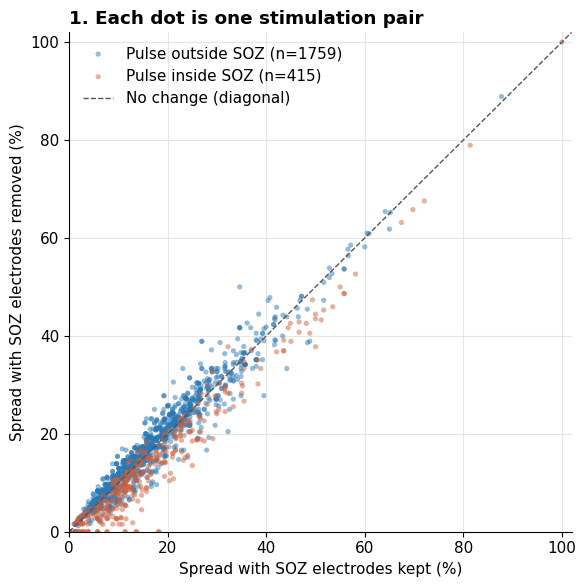

In [31]:
fig, ax = plt.subplots(figsize=(6, 6))
for flag, col, lab in [(False, C_OUT, "Pulse outside SOZ"), (True, C_IN, "Pulse inside SOZ")]:
    d = S[S["stim_in_soz"] == flag]
    ax.scatter(d["spread_all"], d["spread_no_soz"], s=14, alpha=0.5, color=col,
               edgecolor="none", label=f"{lab} (n={len(d)})")
m = max(S["spread_all"].max(), S["spread_no_soz"].max()) + 2
ax.plot([0, m], [0, m], color="#555", lw=1, ls="--", label="No change (diagonal)")
ax.set_xlim(0, m); ax.set_ylim(0, m)
ax.set_xlabel("Spread with SOZ electrodes kept (%)")
ax.set_ylabel("Spread with SOZ electrodes removed (%)")
ax.set_title("1. Each dot is one stimulation pair", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

size of the change, and pulses inside vs. outside the SOZ

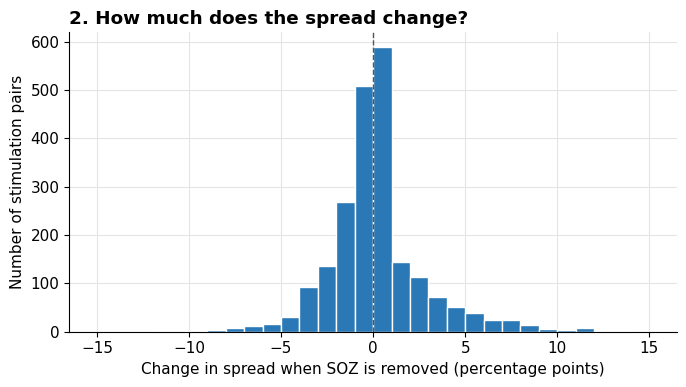

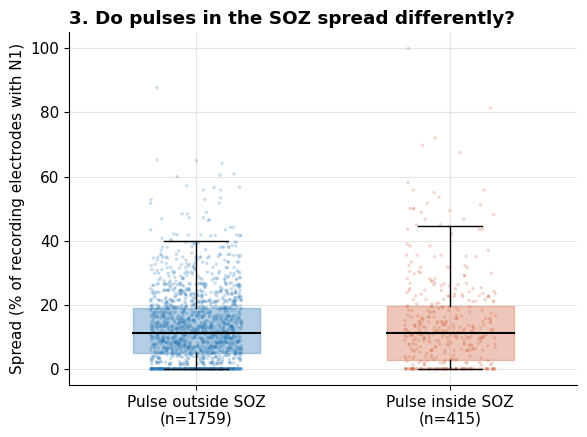

In [32]:
# Plot 2
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(S["change"], bins=np.arange(-15, 15.5, 1), color=C_OUT, edgecolor="white")
ax.axvline(0, color="#555", lw=1, ls="--")
ax.set_xlabel("Change in spread when SOZ is removed (percentage points)")
ax.set_ylabel("Number of stimulation pairs")
ax.set_title("2. How much does the spread change?", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

# Plot 3
fig, ax = plt.subplots(figsize=(6, 4.5))
data = [S.loc[~S["stim_in_soz"], "spread_all"], S.loc[S["stim_in_soz"], "spread_all"]]
bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=False,
                medianprops=dict(color="black", lw=1.5))
for patch, col in zip(bp["boxes"], [C_OUT, C_IN]):
    patch.set_facecolor(col); patch.set_alpha(0.35); patch.set_edgecolor(col)
rng = np.random.default_rng(0)
for i, (d, col) in enumerate(zip(data, [C_OUT, C_IN]), start=1):
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(d)), d, s=6, alpha=0.25, color=col, edgecolor="none")
ax.set_xticks([1, 2], [f"Pulse outside SOZ\n(n={len(data[0])})", f"Pulse inside SOZ\n(n={len(data[1])})"])
ax.set_ylabel("Spread (% of recording electrodes with N1)")
ax.set_title("3. Do pulses in the SOZ spread differently?", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

change per patient

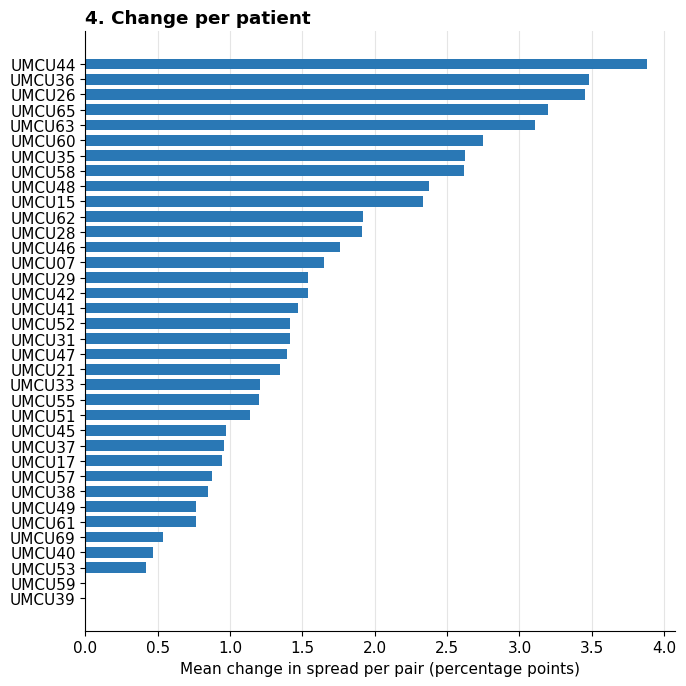

In [33]:
P = S.groupby("patient")["change"].apply(lambda x: x.abs().mean()).sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh([p.replace("sub-ccepAge", "") for p in P.index], P.values, color=C_OUT, height=0.7)
ax.set_xlabel("Mean change in spread per pair (percentage points)")
ax.set_title("4. Change per patient", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

SOZ patients left after each exclusion rule

In [34]:
from src.paths import channels_tsv

out = []
for p in cc:
    el = electrodes_tsv(p["id"], p["ses"]).set_index("name")
    if not el["soz"].eq("yes").any():
        continue
    D = p["nativeElecDistances"]                       # same order as channel_names
    st = dict(patient=p["id"], any_soz=True, surface=False, labelled=False,
              good=False, not_resected=False, far_13mm=False)
    for r in runs(p):
        names = list(r["channel_names"])
        rec = el.reindex(names)
        ch = channels_tsv(p["id"], p["ses"], r["runName"]).set_index("name")
        good = ch.reindex(names)["status"].eq("good").values
        soz = rec["soz"].eq("yes").values
        surf = rec["group"].isin(["grid", "strip"]).values
        lab = (pd.to_numeric(rec["Destrieux_label"], errors="coerce") > 0).values & rec["hemisphere"].isin(["L", "R"]).values
        res = rec["resected"].eq("yes").values
        m1 = soz & surf; m2 = m1 & lab; m3 = m2 & good; m4 = m3 & ~res
        st["surface"] |= m1.any(); st["labelled"] |= m2.any()
        st["good"] |= m3.any(); st["not_resected"] |= m4.any()
        for pair in r["stimpair_names"]:
            si = [names.index(x) for x in pair.split("-") if x in names]
            far = (D[:, si].min(axis=1) >= 13) & ~np.isin(np.arange(len(names)), si)
            if (m4 & far).any():
                st["far_13mm"] = True
                break
    out.append(st)

T = pd.DataFrame(out).set_index("patient")
print(T.sum())                       # patients still having SOZ after each step
T[~T["far_13mm"]]                    # patients whose SOZ is fully removed by the other rules

any_soz         36
surface         34
labelled        34
good            34
not_resected    21
far_13mm        21
dtype: int64


,any_soz,surface,labelled,good,not_resected,far_13mm
patient,,,,,,
sub-ccepAgeUMCU17,True,True,True,True,False,False
sub-ccepAgeUMCU21,True,True,True,True,False,False
sub-ccepAgeUMCU26,True,True,True,True,False,False
sub-ccepAgeUMCU31,True,True,True,True,False,False
sub-ccepAgeUMCU33,True,True,True,True,False,False
sub-ccepAgeUMCU38,True,True,True,True,False,False
sub-ccepAgeUMCU39,True,False,False,False,False,False
sub-ccepAgeUMCU41,True,True,True,True,False,False
sub-ccepAgeUMCU49,True,True,True,True,False,False


ROC curve with the area under it -  basically answers if modelling helps us with rest of Soz

2092 electrodes | 36 patients | AUC = 0.61


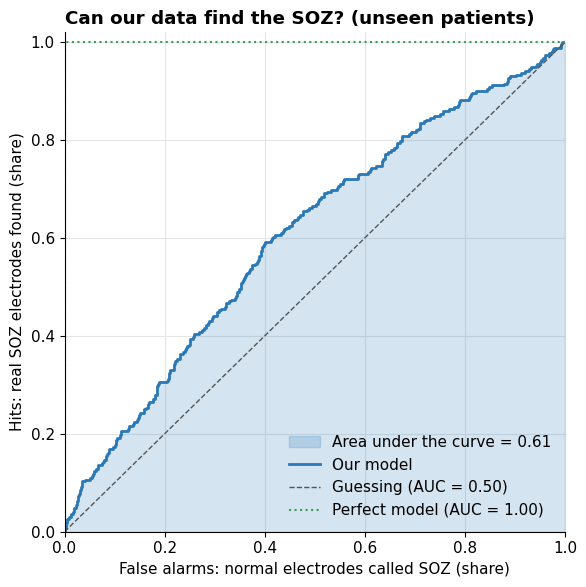

In [36]:
import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score

# 1) three numbers per electrode
feats = []
for p in cc:
    el = electrodes_tsv(p["id"], p["ses"]).set_index("name")
    acc = {}
    new = lambda: dict(rec_n=0, rec_hits=0, lat=[], stim_n=0, stim_hits=0)
    for r in runs(p):
        n1, tt = r["n1_peak_sample"], r["tt"]
        has = ~np.isnan(n1)
        for i, ch in enumerate(r["channel_names"]):          # as recording electrode
            a = acc.setdefault(ch, new())
            a["rec_n"] += n1.shape[1]
            a["rec_hits"] += has[i].sum()
            a["lat"] += list(tt[n1[i][has[i]].astype(int) - 1] * 1000)
        for j, pair in enumerate(r["stimpair_names"]):       # as stimulated electrode
            for e in pair.split("-"):
                a = acc.setdefault(e, new())
                a["stim_n"] += 1
                a["stim_hits"] += has[:, j].sum()
    for ch, a in acc.items():
        if ch not in el.index:
            continue
        feats.append(dict(
            patient=p["id"], soz=el.loc[ch, "soz"] == "yes", group=el.loc[ch, "group"],
            in_rate=a["rec_hits"] / a["rec_n"] if a["rec_n"] else np.nan,
            mean_lat=np.mean(a["lat"]) if a["lat"] else np.nan,
            out_resp=a["stim_hits"] / a["stim_n"] if a["stim_n"] else np.nan,
        ))
F = pd.DataFrame(feats)

# 2) only annotated patients, surface electrodes
annotated = F.groupby("patient")["soz"].transform("any")
D = F[annotated & (F["group"] != "depth")].dropna(subset=["in_rate", "mean_lat", "out_resp"])
X = D[["in_rate", "mean_lat", "out_resp"]].values
y = D["soz"].values

# 3) model, always tested on unseen patients
model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced"))
prob = cross_val_predict(model, X, y, groups=D["patient"], cv=GroupKFold(5),
                         method="predict_proba")[:, 1]
auc = roc_auc_score(y, prob)
print(len(D), "electrodes |", D["patient"].nunique(), "patients | AUC =", round(auc, 2))

# 4) ROC curve
fpr, tpr, _ = roc_curve(y, prob)
fig, ax = plt.subplots(figsize=(6, 6))
ax.fill_between(fpr, tpr, color="#2a78b5", alpha=0.2, label=f"Area under the curve = {auc:.2f}")
ax.plot(fpr, tpr, color="#2a78b5", lw=2, label="Our model")
ax.plot([0, 1], [0, 1], color="#555", ls="--", lw=1, label="Guessing (AUC = 0.50)")
ax.plot([0, 0, 1], [0, 1, 1], color="#3a9d5d", ls=":", lw=1.5, label="Perfect model (AUC = 1.00)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel("False alarms: normal electrodes called SOZ (share)")
ax.set_ylabel("Hits: real SOZ electrodes found (share)")
ax.set_title("Can our data find the SOZ? (unseen patients)", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()